In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
from itertools import product
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize
import seaborn as sns
import pandas as pd



In [2]:
class data():
    def __init__(self,folder,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3):
        self.folder = folder
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.color=''
        self.BG=BG
        self.BG_ds=BG_ds
        self.g_err=g_err
        self.i_err=i_err
        self.footprint=footprint
        self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/'
        
    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/{self.period}_{self.BG_ds}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
        self.fluxes=self.fluxes.where((self.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(self.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{self.path}/gosat_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.gosat=self.gosat.drop_dims(['time','latitude','longitude'])
        self.gosat=self.gosat.where((self.gosat.release_time>=pd.to_datetime(self.start_date))&(self.gosat.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.gosat=self.gosat.where((self.gosat.release_lat>analy_region_lat[0])&(self.gosat.release_lat<analy_region_lat[1])&(self.gosat.release_lon>analy_region_lon[0])&(self.gosat.release_lon<analy_region_lon[1]),drop=True)

    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{self.path}/insitu_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.insitu=self.insitu.drop_dims(['time','latitude','longitude'])
        self.insitu=self.insitu.where((self.insitu.release_time>=pd.to_datetime(self.start_date))&(self.insitu.release_time<=pd.to_datetime(self.end_date)),drop=True)
        #self.insitu=self.insitu.where((self.insitu.release_lat>analy_region_lat[0])&(self.insitu.release_lat<analy_region_lat[1])&(self.insitu.release_lon>analy_region_lon[0])&(self.insitu.release_lon<analy_region_lon[1]),drop=True)
    def read_tccon(self):
        self.tccon=xr.open_dataset(f'{self.path}/TCCON_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.tccon=self.tccon.drop_dims(['time','latitude','longitude'])
        self.tccon=self.tccon.where((self.tccon.release_time>=pd.to_datetime(self.start_date))&(self.tccon.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.tccon=self.tccon.where((self.tccon.release_lat>analy_region_lat[0])&(self.tccon.release_lat<analy_region_lat[1])&(self.tccon.release_lon>analy_region_lon[0])&(self.tccon.release_lon<analy_region_lon[1]),drop=True)

    def read_data(self):
        self.read_fluxes()
        self.read_gosat()
        self.read_insitu()
        self.read_tccon()

In [3]:
analy_region_lat=[2,66]
analy_region_lon=[-144,-52]

# four_times_four 
res=2
n_regions=[6,8] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [4]:
period='20191001-20230331'
analysis_start_date, analysis_end_date =dt.date(2020,1,1), dt.date(2022,12,31)  
start_date, end_date =dt.date(2019,10,1), dt.date(2023,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/3years/doppelpeak/'

# Fire Flux

In [ ]:
GFED4=xr.open_dataset('/work/bb1170/RUN/b383736/data/GFED/GFED4_co2_larger_2x2.nc')
GFED4

<xarray.Dataset> Size: 3MB
Dimensions:         (time: 157, latitude: 32, longitude: 46)
Coordinates:
  * time            (time) datetime64[ns] 1kB 2019-12-30 ... 2022-12-26
  * latitude        (latitude) float32 128B 65.0 63.0 61.0 59.0 ... 7.0 5.0 3.0
  * longitude       (longitude) float32 184B -143.0 -141.0 ... -55.0 -53.0
Data variables:
    CO2             (time, latitude, longitude) float64 2MB ...
    grid_cell_area  (time, latitude, longitude) float32 924kB ...

In [ ]:
GFED5=xr.open_dataset('/work/bb1170/RUN/b383736/data/GFED/GFED5_co2_larger_2x2.nc')
GFED5['CO2']=(GFED5.CO2/GFED4.grid_cell_area).assign_attrs(units='kgCO2/(m^2 s)')
GFED5

NameError: name 'GFED4' is not defined

<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2303054/3032712326.py:21: SyntaxWarning: invalid escape sequence '\m'
  axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')


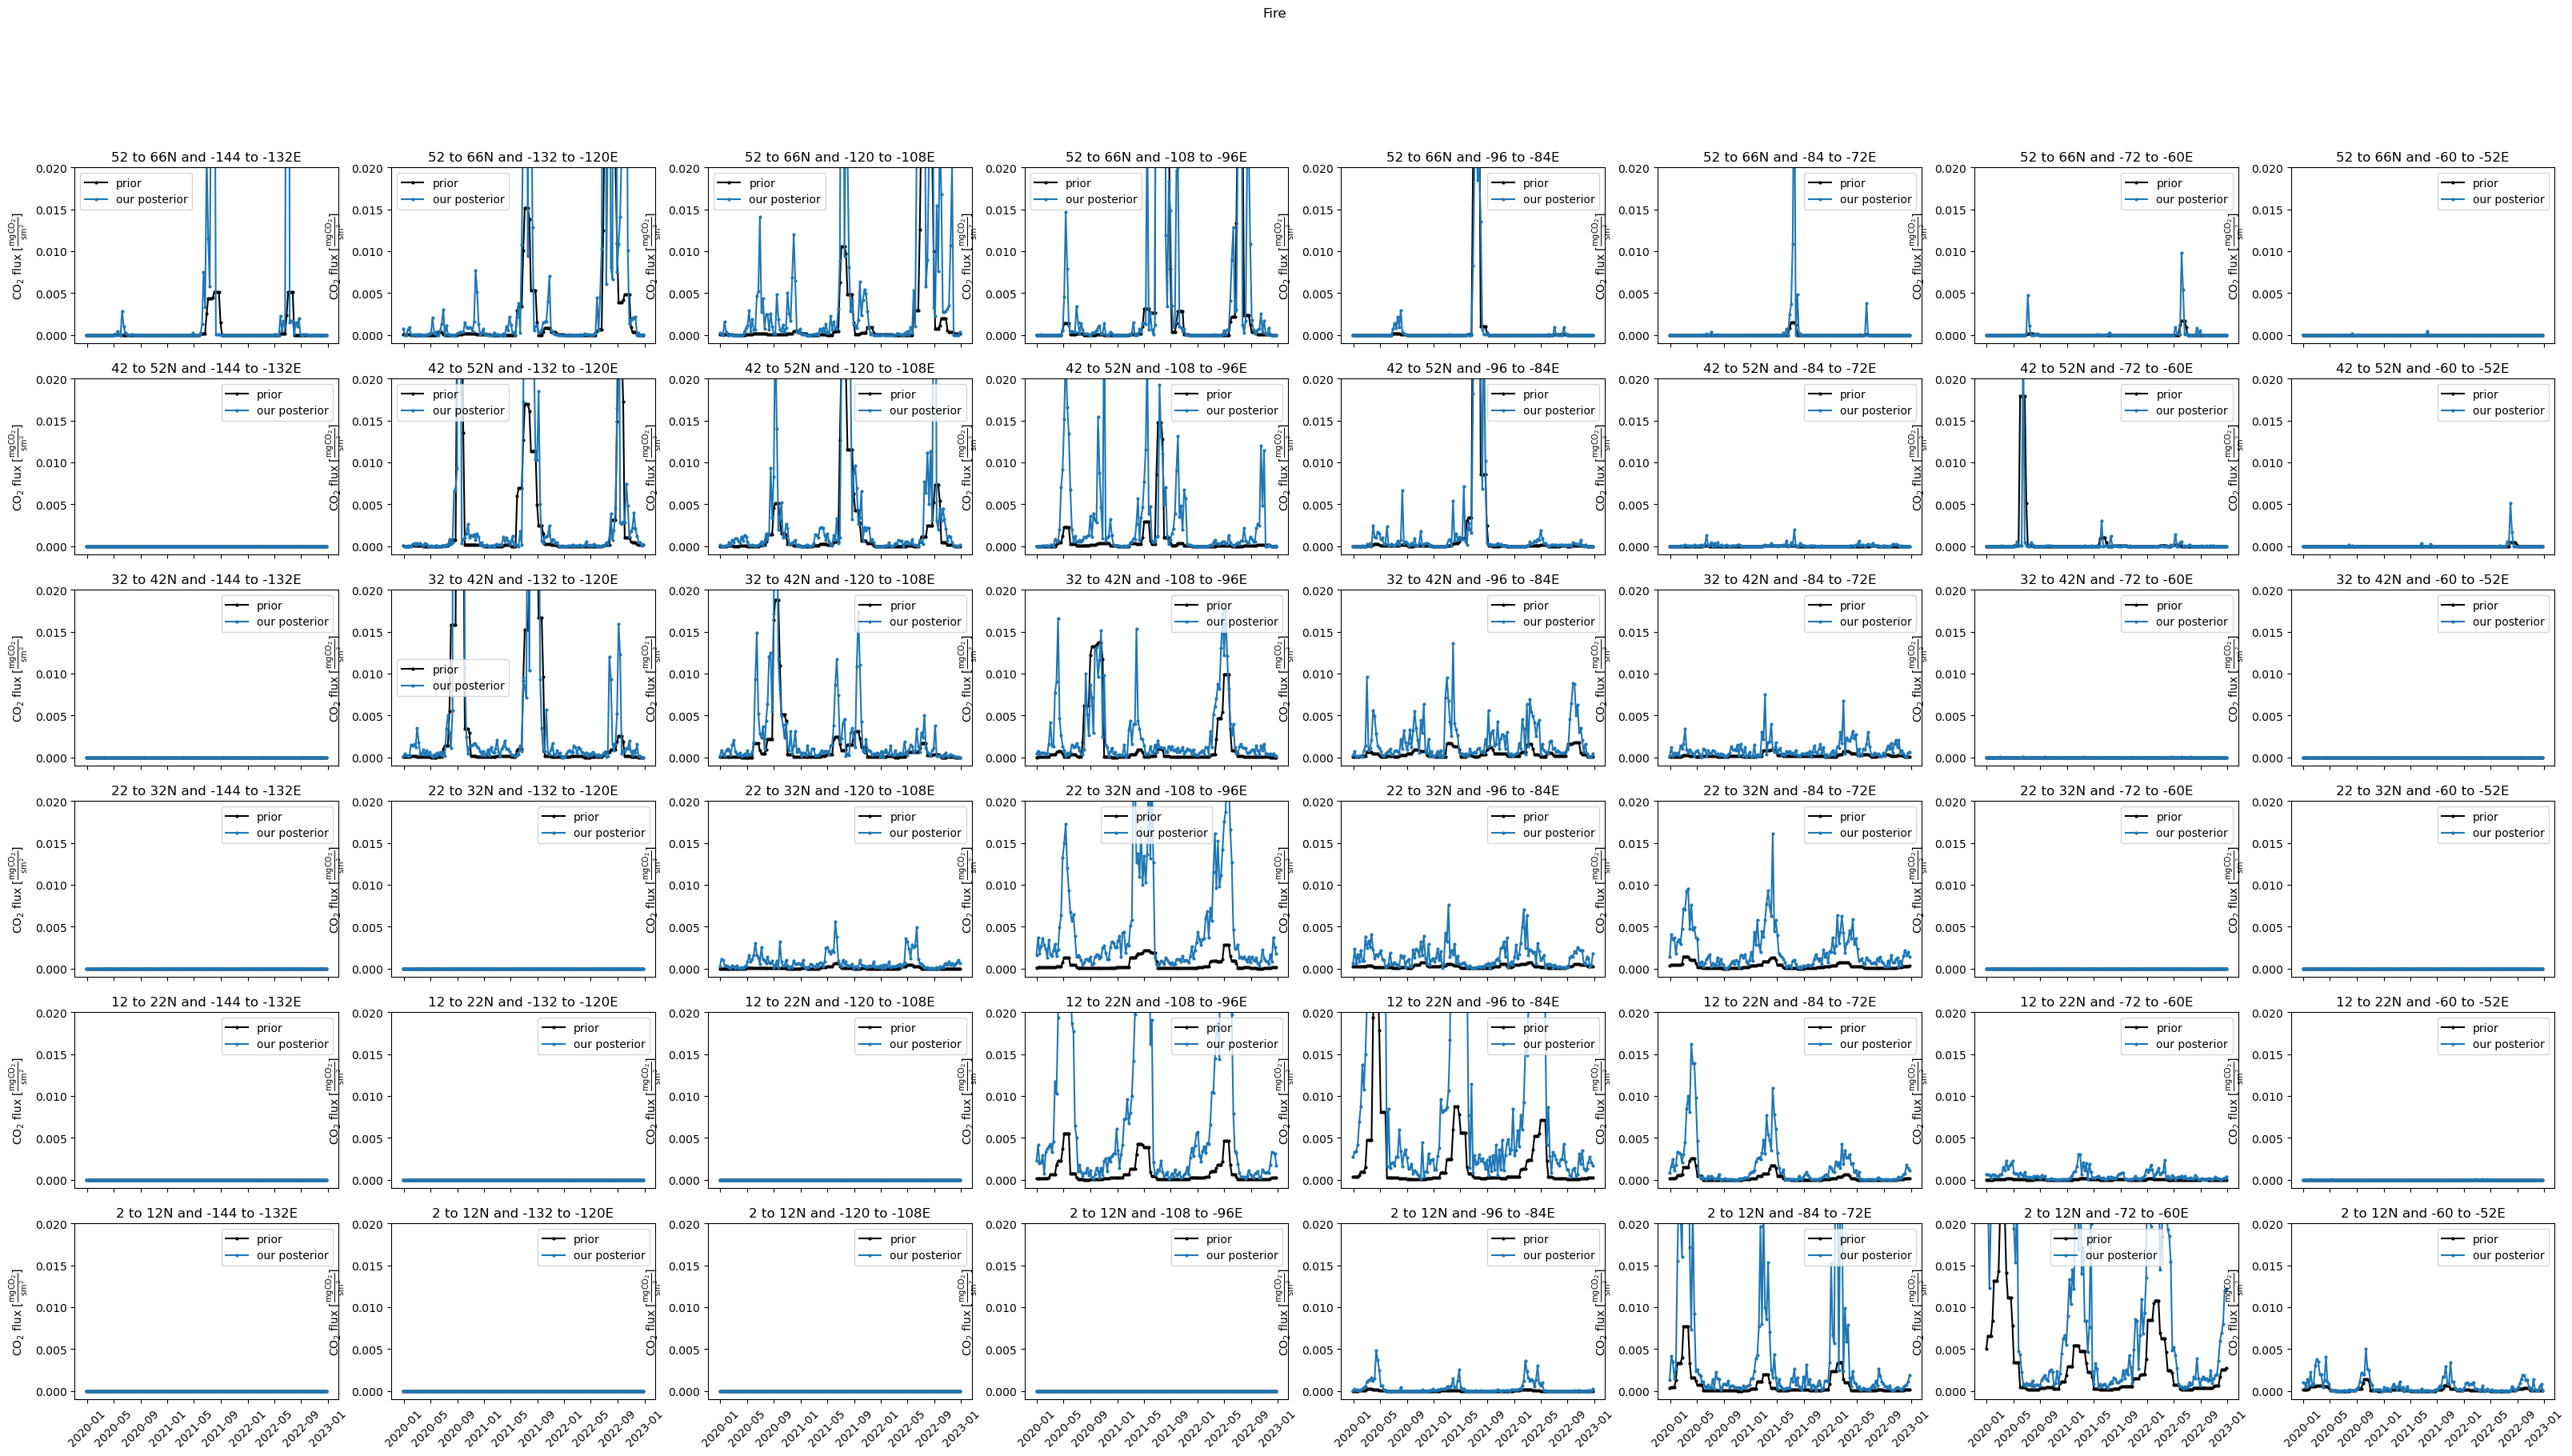

In [ ]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
fig.suptitle('Fire')
min,max=-0.001,0.02
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        s=0
        temp=GFED4.where(((GFED4.latitude>= regions_lat[-i-2]) &(GFED4.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        #temp=temp.where(temp.time.dt.year==2021,drop=True)
        axs[i,j].plot(temp.time, temp.CO2*1e6, c='black', marker='o', markersize=2, label=f'prior')

        temp=GFED5.where(((GFED5.latitude>= regions_lat[-i-2]) &(GFED5.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        #temp=temp.where(temp.time.dt.year==2021,drop=True)
        axs[i,j].plot(temp.time, temp.CO2*1e6, c=default_colors[0], marker='o', markersize=2, label=f'our posterior')
    
        axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')
        axs[i,j].legend()
        axs[i,j].set_ylim(min,max)
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        if i !=n_regions[0]-1:
            axs[i,j].set_xticklabels([])  # Remove X-axis labels
        else:
            axs[i,j].tick_params(axis='x', labelrotation=45)

        #axs[i,j].tight_layout()
plt.savefig(f'{savefig}/regional_GFED4_5_fire_larger_full_time.png',bbox_inches='tight')#,transparent=True)
plt.show()
plt.close()

In [41]:
path='inversions_new/TM5_3_years/'
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

inversion=data(path,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3)
inversion.read_data()

In [42]:
stations=np.unique(inversion.insitu.file.values)
stations

array(['co2_amt_surface-pfp_1_allvalid-107magl.nc',
       'co2_amt_tower-insitu_1_allvalid-107magl.nc',
       'co2_bmw_surface-flask_1_representative.nc',
       'co2_bra_surface-insitu_6_allvalid.nc',
       'co2_cps_surface-insitu_6_allvalid.nc',
       'co2_egb_surface-insitu_6_allvalid.nc',
       'co2_esp_surface-insitu_6_allvalid.nc',
       'co2_est_surface-insitu_6_allvalid.nc',
       'co2_etl_surface-insitu_6_allvalid.nc',
       'co2_fsd_surface-insitu_6_allvalid.nc',
       'co2_key_surface-flask_1_representative.nc',
       'co2_lef_tower-insitu_1_allvalid-396magl.nc',
       'co2_lew_surface-pfp_1_allvalid-95magl.nc',
       'co2_llb_surface-insitu_6_allvalid.nc',
       'co2_mwo_surface-pfp_1_allvalid-46magl.nc',
       'co2_omp_surface-insitu_68_allhours.nc',
       'co2_sct_surface-pfp_1_allvalid-305magl.nc',
       'co2_sct_tower-insitu_1_allvalid-305magl.nc',
       'co2_sgp_surface-flask_1_representative.nc',
       'co2_sgp_surface-insitu_64_allvalid-60magl.nc',


In [43]:
inversion.insitu

<xarray.Dataset> Size: 5MB
Dimensions:                                              (pointspec: 13451)
Coordinates:
  * pointspec                                            (pointspec) int64 108kB ...
    height                                               float32 4B 30.0
Data variables: (12/48)
    release_num                                          (pointspec) float64 108kB ...
    release_day                                          (pointspec) datetime64[ns] 108kB ...
    Unnamed: 0                                           (pointspec) float64 108kB ...
    release_time                                         (pointspec) datetime64[ns] 108kB ...
    file                                                 (pointspec) object 108kB ...
    release_lat                                          (pointspec) float64 108kB ...
    ...                                                   ...
    ref_COLA_diff                                        (pointspec) float64 108kB ...
    ref_GCASv2_diff                                      (pointspec) float64 108kB ...
    ref_UoE_diff                                         (pointspec) float64 108kB ...
    ref_IAPCAS_diff                                      (pointspec) float64 108kB ...
    ref_MIROC_diff                                       (pointspec) float64 108kB ...
    ref_NTFVAR_diff                                      (pointspec) float64 108kB ...
Attributes: (12/37)
    Conventions:            CF-1.6
    title:                  FLEXPART model output
    git:                    ffadcb5 Fri Sep 19 15:51:15 2025 +0000
    source:                 Version 11.0 (2023-07-11) model output
    history:                2026-06-30 15:04 +0200  created by b383736 on l40...
    references:             Stohl et al., Atmos. Chem. Phys., 2005, doi:10.51...
    ...                     ...
    ind_source:             1
    ind_receptor:           2
    mquasilag:              0
    nested_output:          0
    sfc_only:               0
    linit_cond:             0

In [49]:
i=0
for station in stations:
    if station in ['co2_fsd_surface-insitu_6_allvalid.nc','co2_cps_surface-insitu_6_allvalid.nc','co2_lef_tower-insitu_1_allvalid-396magl.nc','co2_amt_surface-pfp_1_allvalid-107magl.nc','co2_amt_tower-insitu_1_allvalid-107magl.nc', 'co2_sgp_surface-insitu_64_allvalid-60magl.nc','co2_sgp_surface-flask_1_representative.nc','co2_wbi_surface-pfp_1_allvalid-379magl.nc','co2_wbi_tower-insitu_1_allvalid-379magl.nc']:
        fig,axs=plt.subplots(1,1,figsize=(14,4))
        #fig.suptitle(f'Measured/Modeled In-Situ, {station[4:7]}',fontsize=14)
        default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
        temp=inversion.insitu.where(( inversion.insitu.file==station),drop=True)
        temp['diurnal']=temp.real_co2-temp.co2
        temp['co2_modeled_posterior']=temp.posterior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['co2_modeled_prior']=temp.prior_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        temp['co2_modeled_TM5']=temp.ref_RemoteC_IS_val+temp['TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background']+temp.diurnal
        if len(temp.pointspec)!=0:

            # our posterior
            axs.plot(temp.release_time, temp.co2_modeled_posterior, marker='o', color=default_colors[0], markersize=4,label='our modeled')
            # prior
            axs.plot(temp.release_time, temp.co2_modeled_prior, marker='o', color=default_colors[1], markersize=4,label='prior modeled')
            # measured
            axs.plot(temp.release_time, temp.real_co2, marker='o', color='black', markersize=4,label='measured')
            # TM5-4DVar
            #axs.plot(temp_mean.release_week, temp_mean.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), marker='o', color='grey', markersize=4,label='TM5-4DVar modeled', alpha=0.5)
            #axs.fill_between(temp_min.release_week, temp_min.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']),temp_max.co2_modeled_TM5.mean(dim=['release_box_lat', 'release_box_lon']), color='grey', alpha=0.1) 
            axs.legend()
        print(station)
        if 'flask' in station:
            label=f'{station[4:7]} flask'
        if 'tower' in station:
            label=f'{station[4:7]} tower'
        if 'pfp' in station:
            label=f'{station[4:7]} PFP'
        if 'surface-insitu' in station:
            label=f'{station[4:7]} insitu'
        axs.set_ylabel(label,fontsize=14)
        axs.set_ylim(380,450)
        axs.grid(visible=True, which='major', axis='both', alpha=0.2)
        axs.set_xticks(pd.date_range(analysis_start_date,analysis_end_date,freq='MS'))
        axs.tick_params(axis='x', labelrotation=45)
        axs.set_xlim(analysis_start_date,analysis_end_date)
        plt.tight_layout()
        plt.savefig(f'{savefig}/measurement_timeline_IS_modeled_measured_{station}.png',bbox_inches='tight')#,transparent=True)
        #plt.show()
        plt.close()


co2_amt_surface-pfp_1_allvalid-107magl.nc
co2_amt_tower-insitu_1_allvalid-107magl.nc
co2_cps_surface-insitu_6_allvalid.nc
co2_fsd_surface-insitu_6_allvalid.nc
co2_lef_tower-insitu_1_allvalid-396magl.nc
co2_sgp_surface-flask_1_representative.nc
co2_sgp_surface-insitu_64_allvalid-60magl.nc
co2_wbi_surface-pfp_1_allvalid-379magl.nc
co2_wbi_tower-insitu_1_allvalid-379magl.nc


# Temperature and soil water

In [44]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [45]:
metero=xr.open_dataset('/work/bb1170/RUN/b383736/data/ERA5_daten/meterological/data_stream-moda.nc')
metero= metero.assign_coords(longitude=((metero.longitude + 180) % 360) - 180).sortby("longitude")
metero=metero.where((metero.valid_time.dt.date>=dt.date(2008,12,29))&(metero.valid_time.dt.date<=dt.date(2023,1,2)))
metero=metero.where((metero.latitude>=analy_region_lat[0]-1)&(metero.latitude<=analy_region_lat[1]+1)&(metero.longitude>=analy_region_lon[0]-1)&(metero.longitude<=analy_region_lon[1]+1), drop=True)
metero=metero.coarsen(latitude=5, longitude=5).mean(['latitude','longitude'])


In [46]:
savefig='figures_2/3years/doppelpeak/'

In [47]:
metero_october=metero.where(metero.valid_time.dt.month==10, drop=True)
metero_october

<xarray.Dataset> Size: 1MB
Dimensions:     (valid_time: 16, latitude: 60, longitude: 116)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 128B 2009-10-01 ... 2024-10-01
  * latitude    (latitude) float64 480B 48.7 48.2 47.7 47.2 ... 20.2 19.7 19.2
  * longitude   (longitude) float64 928B -126.7 -126.2 -125.7 ... -69.7 -69.2
    number      int64 8B 0
    expver      (valid_time) <U4 256B '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    t2m         (valid_time, latitude, longitude) float32 445kB nan nan ... nan
    swvl3       (valid_time, latitude, longitude) float32 445kB nan nan ... nan
    tp          (valid_time, latitude, longitude) float32 445kB nan nan ... nan
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-02-06T14:04 GRIB to CDM+CF via cfgrib-0.9.1...

In [48]:
def plot_map(data,label,ax,cmap='viridis',vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,rasterized=True, cbar_kwargs={'location':'bottom', 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(15)
    plot.colorbar.ax.tick_params(labelsize=15)

    '''
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')'''
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 14}
    gl.ylabel_style = {'size': 14}
    ax.grid(c='lightgrey')
    ax.set_xlim(analy_region_lon[0],analy_region_lon[1]) 
    ax.set_ylim(analy_region_lat[0],analy_region_lat[1])
    ax.tick_params(labelsize=20)
    ax.set_title('')

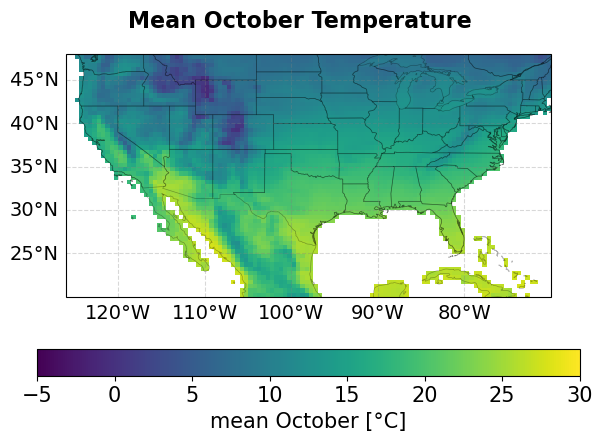

In [49]:

fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Mean October Temperature", fontsize=16, fontweight='bold')
#fig.subplots_adjust(right=0.85)
metero_octobet_mean_temp=(metero_october.mean('valid_time').t2m-273.15)
plot_map(metero_octobet_mean_temp,r'mean October [°C]',axs,vmin=-5,vmax=30)
plt.savefig(f'{savefig}/map_mean_october_temperature.pdf',bbox_inches='tight',dpi=500)
plt.show()

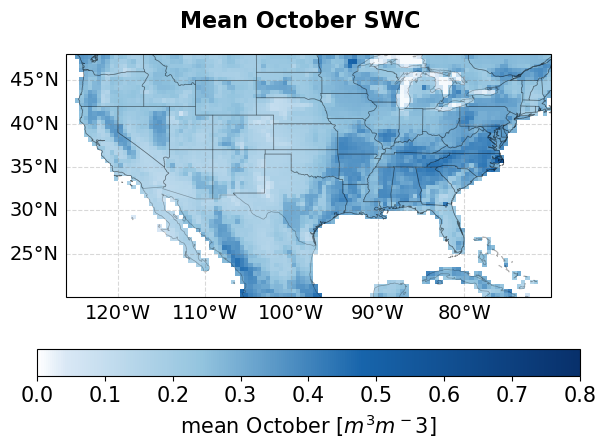

In [50]:
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Mean October SWC", fontsize=16, fontweight='bold')
#fig.subplots_adjust(right=0.85)
metero_octobet_mean_soil_water=(metero_october.mean('valid_time').swvl3)
cmap = LinearSegmentedColormap.from_list( 'white_blue',[(0.00, 'white'), (0.05, plt.cm.Blues(0.15)), (0.30, plt.cm.Blues(0.4)), (0.60, plt.cm.Blues(0.80)), (1.00, plt.cm.Blues(1.00)) ])

plot_map(metero_octobet_mean_soil_water,r'mean October [$m^3 m^-3$]',axs,cmap=cmap,vmin=0,vmax=0.8)
plt.savefig(f'{savefig}/map_mean_october_soil_water.pdf',bbox_inches='tight',dpi=500)
plt.show()

In [51]:
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"SWC Oct {year}", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(metero_october.where(metero_october.valid_time.dt.year==year,drop=True)).mean('valid_time').swvl3
    temp=temp
    plot_map(temp,r'$m^3 m^{-3}$',axs,cmap=cmap,vmin=0,vmax=0.8)
    plt.savefig(f'{savefig}/map_october_soil_water_{year}.pdf',bbox_inches='tight',dpi=500)
    plt.close()

In [52]:
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(fr"SWC Oct {year} - $\overline{{\mathbf{{SWC\ Oct}}}}$", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(metero_october.where(metero_october.valid_time.dt.year==year,drop=True)).mean('valid_time').swvl3
    temp=temp-metero_octobet_mean_soil_water
    plot_map(temp,r'$m^3 m^{-3}$',axs,cmap='RdBu',vmin=-0.2,vmax=0.2)
    plt.savefig(f'{savefig}/map_october_soil_water_anomaly_{year}.pdf',bbox_inches='tight',dpi=500)
    plt.close()

In [53]:
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"soil water content anomaly per mean 10/{year}", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(metero_october.where(metero_october.valid_time.dt.year==year,drop=True)).mean('valid_time').swvl3
    temp=(temp-metero_octobet_mean_soil_water)/np.abs(metero_octobet_mean_soil_water)
    plot_map(temp,r'',axs,cmap='RdBu',vmin=-1,vmax=1)
    plt.savefig(f'{savefig}/map_october_soil_water_anomaly_per_mean_{year}.png',bbox_inches='tight',dpi=500)
    plt.close()

/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


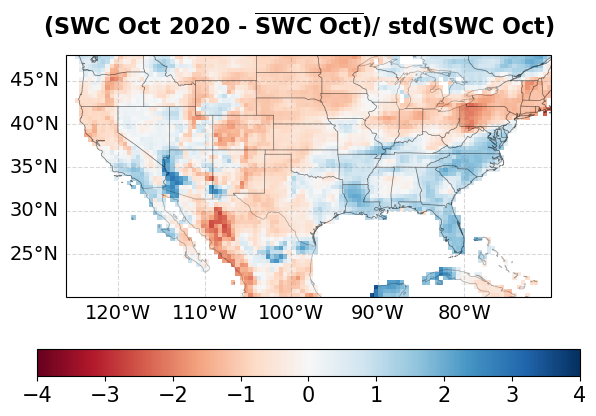

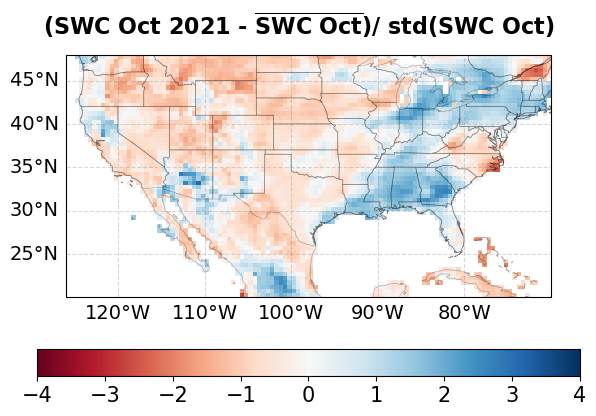

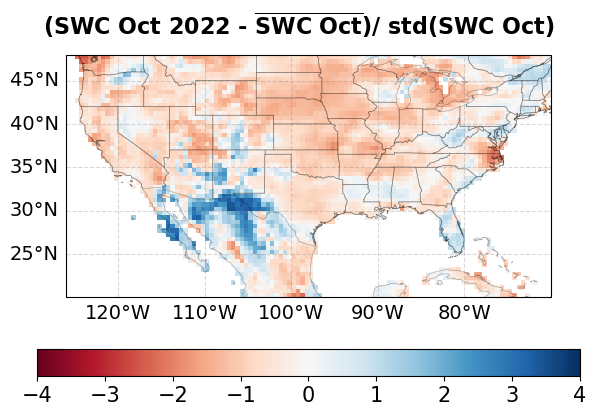

In [54]:
metero_octobet_std_soil_water=(metero_october.std('valid_time').swvl3)
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(fr"(SWC Oct {year} - $\overline{{\mathbf{{SWC\ Oct}}}}$)/ std(SWC Oct) ", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(metero_october.where(metero_october.valid_time.dt.year==year,drop=True)).mean('valid_time').swvl3
    temp=(temp-metero_octobet_mean_soil_water)/np.abs(metero_octobet_std_soil_water)
    plot_map(temp,r'',axs,cmap='RdBu',vmin=-4,vmax=4)
    plt.savefig(f'{savefig}/map_october_soil_water_anomaly_per_std_{year}.pdf',bbox_inches='tight',dpi=500)
    plt.show()

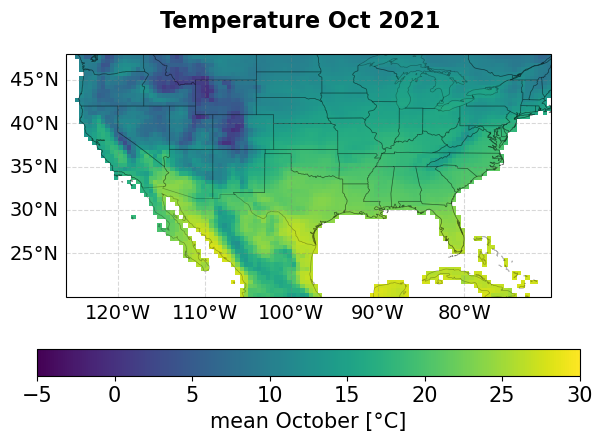

In [55]:
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Temperature Oct 2021", fontsize=16, fontweight='bold')
#fig.subplots_adjust(right=0.85)
metero_octobet_mean_temp=(metero_october.mean('valid_time').t2m-273.15)
metero_october_2021=(metero_october.where(metero_october.valid_time.dt.year==2021,drop=True)).mean('valid_time').t2m-273.15
plot_map(metero_october_2021,r'mean October [°C]',axs,vmin=-5,vmax=30)
plt.savefig(f'{savefig}/map_2021_october_temperature.pdf',bbox_inches='tight',dpi=500)
plt.show()

In [56]:
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"Temperature Oct {year}", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(metero_october.where(metero_october.valid_time.dt.year==year,drop=True)).mean('valid_time').t2m-273.15
    temp=temp
    plot_map(temp,r'°C',axs,vmin=-5,vmax=30)
    plt.savefig(f'{savefig}/map_{year}_october_temperature.pdf',bbox_inches='tight',dpi=500)
    plt.close()

In [57]:
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"T Oct {year} - $\overline{{\mathbf{{T\ Oct}}}}$", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(metero_october.where(metero_october.valid_time.dt.year==year,drop=True)).mean('valid_time').t2m-273.15
    temp=temp-metero_octobet_mean_temp
    plot_map(temp,r'°C',axs,cmap='RdBu_r',vmin=-5,vmax=5)
    plt.savefig(f'{savefig}/map_anomaly_{year}_october_temperature.pdf',bbox_inches='tight',dpi=500)
    plt.close()

<>:3: SyntaxWarning: invalid escape sequence '\o'
<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\ '
<>:3: SyntaxWarning: invalid escape sequence '\o'
<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_1991286/393862004.py:3: SyntaxWarning: invalid escape sequence '\o'
  fig.suptitle(f"T Oct {year} - $\overline{{\mathbf{{T\ Oct}}}}$", fontsize=16, fontweight='bold')
/tmp/ipykernel_1991286/393862004.py:3: SyntaxWarning: invalid escape sequence '\m'
  fig.suptitle(f"T Oct {year} - $\overline{{\mathbf{{T\ Oct}}}}$", fontsize=16, fontweight='bold')
/tmp/ipykernel_1991286/393862004.py:3: SyntaxWarning: invalid escape sequence '\ '
  fig.suptitle(f"T Oct {year} - $\overline{{\mathbf{{T\ Oct}}}}$", fontsize=16, fontweight='bold')


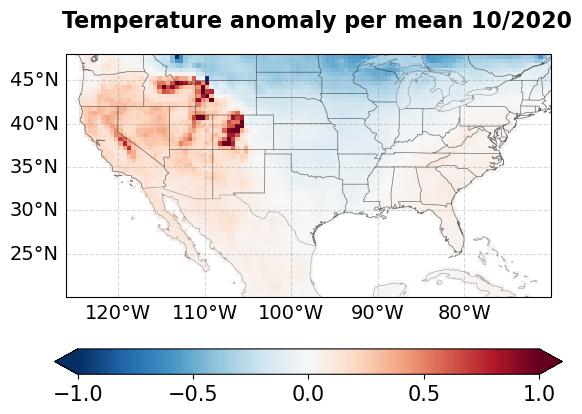

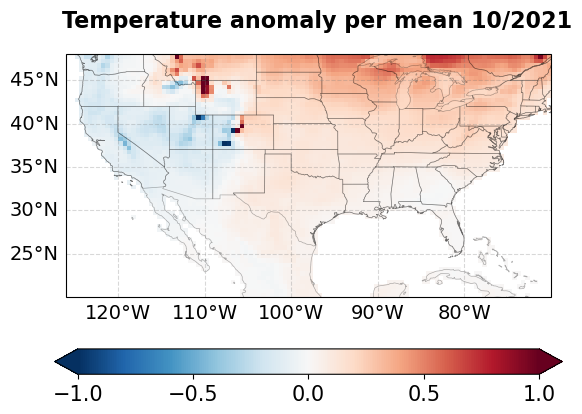

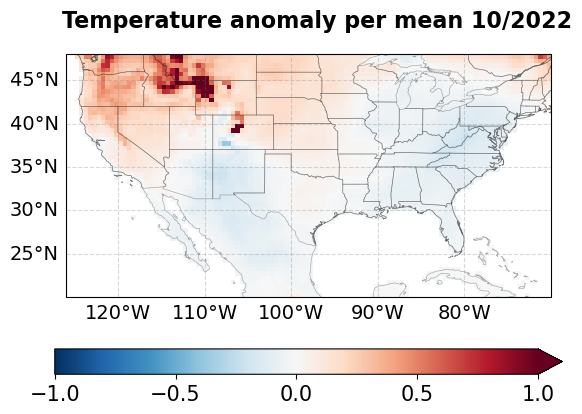

In [58]:
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"Temperature anomaly per mean 10/{year}", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(metero_october.where(metero_october.valid_time.dt.year==year,drop=True)).mean('valid_time').t2m-273.15
    temp=(temp-metero_octobet_mean_temp)/np.abs(metero_octobet_mean_temp)
    plot_map(temp,r'',axs,cmap='RdBu_r',vmin=-1,vmax=1)
    plt.savefig(f'{savefig}/map_anomaly_per_mean_{year}_october_temperature.png',bbox_inches='tight',dpi=500)
    plt.show()

/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


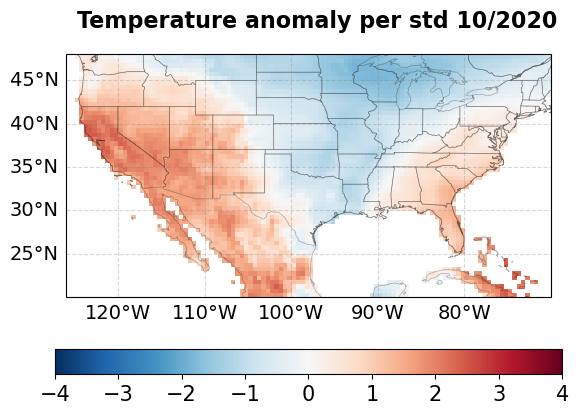

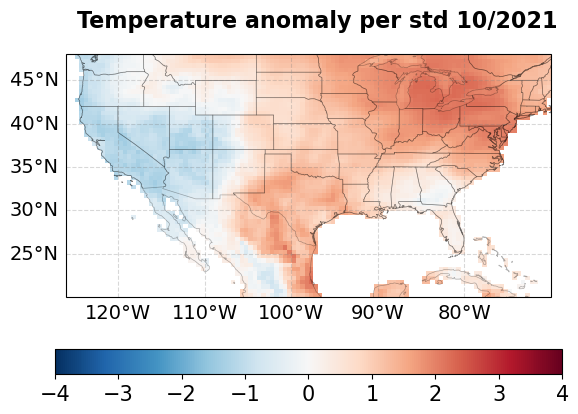

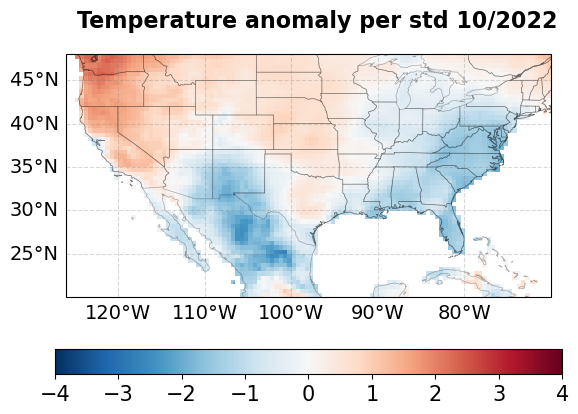

In [59]:
metero_octobet_std_temp=(metero_october.std('valid_time').t2m)

for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"Temperature anomaly per std 10/{year}", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(metero_october.where(metero_october.valid_time.dt.year==year,drop=True)).mean('valid_time').t2m-273.15
    temp=(temp-metero_octobet_mean_temp)/np.abs(metero_octobet_std_temp)
    plot_map(temp,r'',axs,cmap='RdBu_r',vmin=-4,vmax=4)
    plt.savefig(f'{savefig}/map_anomaly_per_std_{year}_october_temperature.png',bbox_inches='tight',dpi=500)
    plt.show()

In [60]:
savefig

'figures_2/3years/doppelpeak/'

# Summer dips meteorology

In [81]:
savefig='figures_2/3years/summer_anomaly/'

In [82]:
summer=[6,7,8]
metero_summer=metero.where((metero.valid_time.dt.month==summer[0])|(metero.valid_time.dt.month==summer[1])|(metero.valid_time.dt.month==summer[2]),drop=True)
metero_summer=metero_summer.where((metero_summer.latitude>=analy_region_lat[0])& (metero_summer.latitude<=analy_region_lat[1]),drop=True)
metero_summer=metero_summer.where((metero_summer.longitude>=analy_region_lon[0])& (metero_summer.longitude<=analy_region_lon[1]),drop=True)

In [ ]:
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("mean Summer Temperature", fontsize=16, fontweight='bold')
#fig.subplots_adjust(right=0.85)
metero_summer_mean=(metero_summer.mean('valid_time').t2m-273.15)
plot_map(metero_summer_mean,r'mean October [°C]',axs,vmin=-5,vmax=30)
plt.savefig(f'{savefig}/map_mean_summer_temperature.pdf',bbox_inches='tight',dpi=500)
plt.close()

for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"Temperature JJA {year}", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(metero_summer.where(metero_summer.valid_time.dt.year==year,drop=True)).mean('valid_time').t2m-273.15
    temp=temp
    plot_map(temp,r'°C',axs,vmin=-5,vmax=30)
    plt.savefig(f'{savefig}/map_{year}_summer_temperature.pdf',bbox_inches='tight',dpi=500)
    plt.close()

for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"T Summer {year} - $\overline{{\mathbf{{T\ Summer}}}}$", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(metero_summer.where(metero_summer.valid_time.dt.year==year,drop=True)).mean('valid_time').t2m-273.15
    temp=temp-metero_summer_mean
    plot_map(temp,r'°C',axs,cmap='RdBu_r',vmin=-4,vmax=4)
    plt.savefig(f'{savefig}/map_anomaly_{year}_summer_temperature.pdf',bbox_inches='tight',dpi=500)
    plt.close()

<>:21: SyntaxWarning: invalid escape sequence '\o'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\ '
<>:21: SyntaxWarning: invalid escape sequence '\o'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_1991286/585940708.py:21: SyntaxWarning: invalid escape sequence '\o'
  fig.suptitle(f"T Summer {year} - $\overline{{\mathbf{{T\ Summer}}}}$", fontsize=16, fontweight='bold')
/tmp/ipykernel_1991286/585940708.py:21: SyntaxWarning: invalid escape sequence '\m'
  fig.suptitle(f"T Summer {year} - $\overline{{\mathbf{{T\ Summer}}}}$", fontsize=16, fontweight='bold')
/tmp/ipykernel_1991286/585940708.py:21: SyntaxWarning: invalid escape sequence '\ '
  fig.suptitle(f"T Summer {year} - $\overline{{\mathbf{{T\ Summer}}}}$", fontsize=16, fontweight='bold')


<>:22: SyntaxWarning: invalid escape sequence '\o'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\ '
<>:33: SyntaxWarning: invalid escape sequence '\o'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\ '
<>:22: SyntaxWarning: invalid escape sequence '\o'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\ '
<>:33: SyntaxWarning: invalid escape sequence '\o'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_1991286/3011057317.py:22: SyntaxWarning: invalid escape sequence '\o'
  fig.suptitle(f"SWC Summer {year} - $\overline{{\mathbf{{SWC\ Summer}}}}$", fontsize=16, fontweight='bold')
/tmp/ipykernel_1991286/3011057317.py:22: SyntaxWarning: invalid escape sequence '\m'
  fig.suptitle(f"SWC Summer {year} - $\overline{{\mathbf{{SWC\ Summer}}}}$", fontsize=16, fontweight='bold')


/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


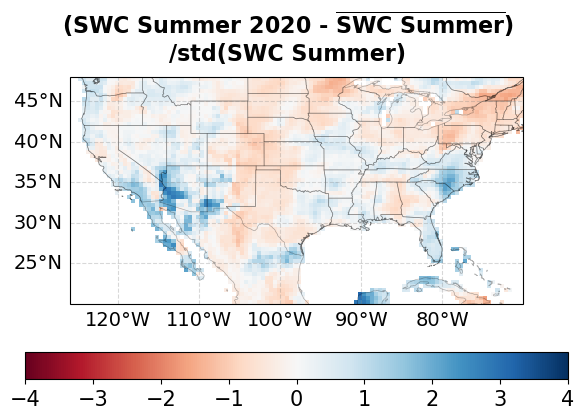

In [64]:
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Mean Summer Soil Water Content", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
metero_summer_mean_soil_water=(metero_summer.mean('valid_time').swvl3)
cmap = LinearSegmentedColormap.from_list( 'white_blue',[(0.00, 'white'), (0.05, plt.cm.Blues(0.15)), (0.30, plt.cm.Blues(0.4)), (0.60, plt.cm.Blues(0.80)), (1.00, plt.cm.Blues(1.00)) ])

plot_map(metero_summer_mean_soil_water,r'mean October [$m^3 m^-3$]',axs,cmap=cmap,vmin=0,vmax=0.8)
plt.savefig(f'{savefig}/map_mean_summer_soil_water.pdf',bbox_inches='tight',dpi=500)
plt.close()

for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"SWC Summer {year}", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(metero_summer.where(metero_summer.valid_time.dt.year==year,drop=True)).mean('valid_time').swvl3
    temp=temp
    plot_map(temp,r'$m^3 m^{-3}$',axs,cmap=cmap,vmin=0,vmax=0.8)
    plt.savefig(f'{savefig}/map_summer_soil_water_{year}.pdf',bbox_inches='tight',dpi=500)
    plt.close()
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"SWC Summer {year} - $\overline{{\mathbf{{SWC\ Summer}}}}$", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(metero_summer.where(metero_summer.valid_time.dt.year==year,drop=True)).mean('valid_time').swvl3
    temp=temp-metero_summer_mean_soil_water
    plot_map(temp,r'$m^3 m^{-3}$',axs,cmap='RdBu',vmin=-0.2,vmax=0.2)
    plt.savefig(f'{savefig}/map_summer_soil_water_anomaly_{year}.pdf',bbox_inches='tight',dpi=500)
    plt.close()

metero_summer_std_soil_water=(metero_summer.std('valid_time').swvl3)
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"(SWC Summer {year} - $\overline{{\mathbf{{SWC\ Summer}}}}$)"+'\n'+"/std(SWC Summer)", fontsize=16, fontweight='bold')
    fig.subplots_adjust(top=0.83)
    temp=(metero_summer.where(metero_summer.valid_time.dt.year==year,drop=True)).mean('valid_time').swvl3
    temp=(temp-metero_summer_mean_soil_water)/np.abs(metero_summer_std_soil_water)
    plot_map(temp,r'',axs,cmap='RdBu',vmin=-4,vmax=4)
    plt.savefig(f'{savefig}/map_summer_soil_water_anomaly_per_std_{year}.pdf',bbox_inches='tight',dpi=500)
    plt.show()
    break

# model anomaly

In [65]:
period='20191001-20230331'
analysis_start_date, analysis_end_date =dt.date(2020,1,1), dt.date(2022,12,31)  
start_date, end_date =dt.date(2019,10,1), dt.date(2023,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/3years/doppelpeak/'

In [66]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [67]:
def plot_map(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax,rasterized=True, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(15)
    plot.colorbar.ax.tick_params(labelsize=15)
     
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 14}
    gl.ylabel_style = {'size': 14}
    ax.grid(c='lightgrey')
    ax.set_xlim(analy_region_lon[0],analy_region_lon[1]) 
    ax.set_ylim(analy_region_lat[0],analy_region_lat[1])
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [68]:
prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_prior_cut_weekly.nc')
#prior=prior.where((prior.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(prior.time<=pd.to_datetime(analysis_end_date)),drop=True)

GFED=xr.open_dataset('/work/bb1170/RUN/b383736/data/GFED/GFED5_co2_larger_2x2_2008_2022.nc')
GFED['CO2']=(GFED.CO2/prior.grid_cell_area).assign_attrs(units='kgCO2/(m^2 s)')



In [69]:
path='inversions_new/TM5_3_years/'
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

inversion=data(path,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3)
inversion.read_data()
inversion.fluxes=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)

inversion.fluxes['CO2_flux_fos']=prior.CO2_flux_fos
inversion.fluxes['CO2_flux_oce']=prior.CO2_flux_oce
inversion.fluxes['CO2_flux_fire']=GFED.CO2
inversion.fluxes['CO2_flux_nee']=inversion.fluxes.TM5_posterior_flux - inversion.fluxes.CO2_flux_fos - GFED.CO2 - inversion.fluxes.CO2_flux_oce
inversion.fluxes

<xarray.Dataset> Size: 105MB
Dimensions:                    (time: 157, latitude: 22, longitude: 36,
                                meas_num: 38270)
Coordinates:
  * time                       (time) datetime64[ns] 1kB 2019-12-30 ... 2022-...
  * latitude                   (latitude) float32 88B 13.0 15.0 ... 53.0 55.0
  * longitude                  (longitude) float32 144B -133.0 -131.0 ... -63.0
  * meas_num                   (meas_num) int64 306kB 0 1 2 ... 38268 38269
    height                     float32 4B 30.0
Data variables:
    TM5_prior_flux             (time, latitude, longitude) float64 995kB 7.43...
    prior_uncertainty          (time, latitude, longitude) float64 995kB 6.24...
    TM5_posterior_flux         (time, latitude, longitude) float64 995kB 7.42...
    TM5_posterior_std          (time, latitude, longitude) float64 995kB 6.24...
    TM5_averaging_kernel_diag  (time, latitude, longitude) float64 995kB 1.34...
    meas                       (meas_num, time) float64 48MB -1.123 ... 5.879
    meas_cov                   (meas_num, time) float64 48MB 4.899 4.899 ... 3.0
    CO2_flux_fos               (time, latitude, longitude) float64 995kB ...
    CO2_flux_oce               (time, latitude, longitude) float64 995kB ...
    CO2_flux_fire              (time, latitude, longitude) float64 995kB 0.0 ...
    CO2_flux_nee               (time, latitude, longitude) float64 995kB -1.0...

In [70]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')

TM54DVar_posterior_flux['CO2_flux_nee']=TM54DVar_posterior_flux['CO2_flux_nee']+TM54DVar_posterior_flux['CO2_flux_fire']-GFED.CO2
TM54DVar_posterior_flux['CO2_flux_fire']=GFED.CO2


In [71]:
GCP=xr.open_dataset('/work/bb1170/RUN/b383736/data/GCP/GCP2024_inversions_2x2_version1_2_20241021_cut_weekly.nc')
GCP=GCP.where((GCP.time>=np.min(TM54DVar_posterior_flux.time.values))&(GCP.time<=np.max(TM54DVar_posterior_flux.time.values)),drop=True)
GCP['CO2_flux_nee']=GCP.land_flux_only_fossil_cement_adjusted-GFED.CO2
GCP['CO2_flux_fire']=GFED.CO2
GCP['CO2_flux_oce']=GCP.ocean_flux_NOT_adjusted
GCP['CO2_flux_fos']=GCP.fossil_fuel_emissions
gcp_names=[]
for i in GCP.ensemble_member:
    gcp_names.append(GCP.sel(ensemble_member=i).ensemble_member_name.values[0].sum())
print(gcp_names)
'''GCP
for ensemble in GCP.ensemble_member:
    letters=GCP.sel(ensemble_member=ensemble).ensemble_member_name.values[0]
    name=''
    for letter in letters:
        name=name+letter
'''
GCP

['CarboScope', 'CAMS', 'CTE', 'NISMON-CO2', 'CT-NOAA', 'CMS-Flux', 'CAMS-Satellite', 'GONGGA', 'COLA', 'GCASv2', 'UoE', 'IAPCAS', 'MIROC', 'NTFVAR']


<xarray.Dataset> Size: 609MB
Dimensions:                                (latitude: 22, longitude: 36,
                                            time: 732, ensemble_member: 14,
                                            nchars: 20)
Coordinates:
  * latitude                               (latitude) float32 88B 13.0 ... 55.0
  * longitude                              (longitude) float32 144B -133.0 .....
  * time                                   (time) datetime64[ns] 6kB 2008-12-...
Dimensions without coordinates: ensemble_member, nchars
Data variables: (12/15)
    ensemble_member_name                   (time, ensemble_member, nchars) object 2MB ...
    cell_area                              (time, latitude, longitude) float64 5MB ...
    land_flux_only_fossil_cement_adjusted  (time, ensemble_member, latitude, longitude) float64 65MB ...
    ocean_flux_NOT_adjusted                (time, ensemble_member, latitude, longitude) float64 65MB ...
    prior_flux_land                        (time, ensemble_member, latitude, longitude) float64 65MB ...
    prior_flux_ocean                       (time, ensemble_member, latitude, longitude) float64 65MB ...
    ...                                     ...
    river_adjustment_ocean                 (time, latitude, longitude) float64 5MB ...
    total_flux                             (time, ensemble_member, latitude, longitude) float64 65MB ...
    CO2_flux_nee                           (time, ensemble_member, latitude, longitude) float64 65MB ...
    CO2_flux_fire                          (time, latitude, longitude) float64 5MB ...
    CO2_flux_oce                           (time, ensemble_member, latitude, longitude) float64 65MB ...
    CO2_flux_fos                           (time, ensemble_member, latitude, longitude) float64 65MB ...
Attributes: (12/18)
    contact:                    Ingrid Luijkx, Wageningen University, ingrid....
    contact_all:                Comma separated email addresses: christian.ro...
    Conventions:                CF-1.8
    creation_date:              2024-10-21
    creator:                    Ingrid Luijkx, Wageningen University, orcid:0...
    crs:                        spherical earth with radius of 6371 km
    ...                         ...
    product_version:            1.0
    project:                    Global Carbon Project, GCB2024
    references:                 Please inform the inverse modelling group whe...
    source:                     Below is a list of the versions of each syste...
    summary:                    In this file, we include the data from the GC...
    title:                      Global CO2 gridded flux fields from 14 atmosp...

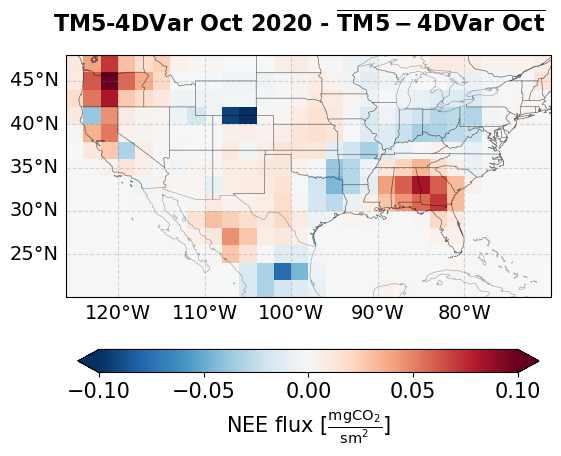

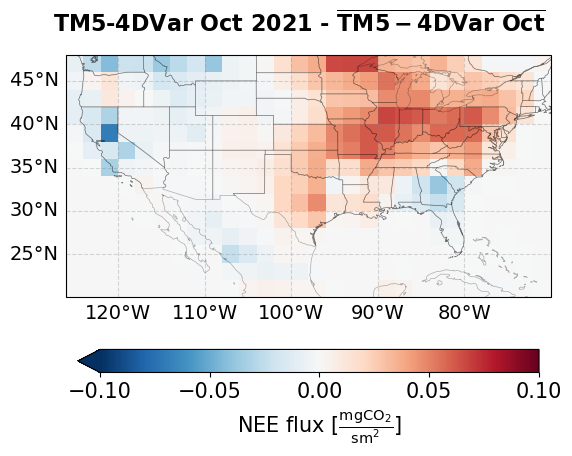

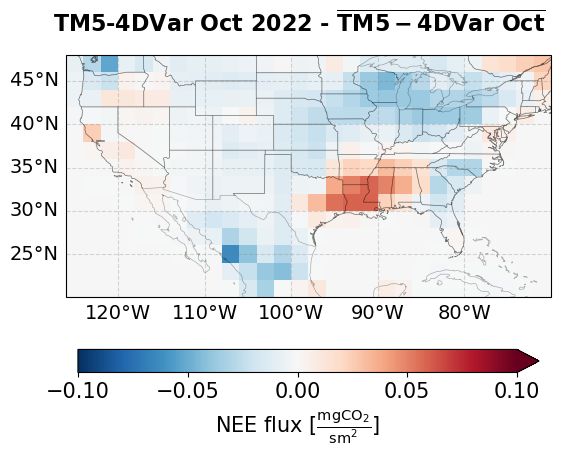

In [73]:
octobers=TM54DVar_posterior_flux.where(TM54DVar_posterior_flux.time.dt.month==10,drop=True)
mean_october_TM5=octobers.mean('time')
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("mean October TM5-4DVar", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
plot_map(mean_october_TM5.CO2_flux_nee*1e6,'mean October total flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.2,vmax=0.2)
#plt.savefig(f'{savefig}/map_mean_october_TM5-4DVar.png',bbox_inches='tight',dpi=500)
plt.close()
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"TM5-4DVar Oct {year}", fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(octobers.where(octobers.time.dt.year==year,drop=True)).mean('time')
    plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.2,vmax=0.2)
    plt.savefig(f'{savefig}/map_mean_october_TM5-4DVar_{year}.pdf',bbox_inches='tight',dpi=500)
    plt.close()
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"TM5-4DVar Oct {year} - "+r'$\overline{\mathbf{TM5-4DVar\ Oct}}$', fontsize=16, fontweight='bold')
    #fig.subplots_adjust(right=0.85)
    temp=(octobers.where(octobers.time.dt.year==year,drop=True)).mean('time') - mean_october_TM5
    plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.1,vmax=0.1)
    plt.savefig(f'{savefig}/anomalies_different_models/map_anomaly_nee_{year}_october_TM5-4DVar.pdf',bbox_inches='tight',dpi=500)
    plt.show()


In [74]:
octobers=inversion.fluxes.where(inversion.fluxes.time.dt.month==10,drop=True)
mean_october=octobers.mean('time')
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Mean October Our Posterior", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
plot_map(mean_october.CO2_flux_nee*1e6,'mean October total flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.2,vmax=0.2)
#plt.savefig(f'{savefig}/map_mean_october_TM5-4DVar.png',bbox_inches='tight',dpi=500)
plt.close()
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"Our Post. Oct {year}", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(octobers.where(octobers.time.dt.year==year,drop=True)).mean('time')
    plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.2,vmax=0.2)
    plt.savefig(f'{savefig}/map_mean_october_posteiror_{year}.pdf',bbox_inches='tight',dpi=500)
    plt.close()
    if year!=2020:
        fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
        fig.suptitle(f"Our Post. Oct {year} - Oct 2020", fontsize=16, fontweight='bold')
        fig.subplots_adjust(right=0.85)
        temp=(octobers.where(octobers.time.dt.year==year,drop=True)).mean('time') -(octobers.where(octobers.time.dt.year==2020,drop=True)).mean('time')
        plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.08,vmax=0.08)
        plt.savefig(f'{savefig}/anomalies_different_models/map_anomaly_nee_{year}_posterior-2020.pdf',bbox_inches='tight',dpi=500)
        plt.close()
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"Our Post. Oct {year} - "+r'$\overline{\mathbf{TM5-4DVar\ Oct}}$', fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(octobers.where(octobers.time.dt.year==year,drop=True)).mean('time') - mean_october_TM5
    plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.08,vmax=0.08)
    plt.savefig(f'{savefig}/anomalies_different_models/map_anomaly_nee_{year}_posterior-TM5.pdf',bbox_inches='tight',dpi=500)
    plt.close()
    


In [75]:
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("mean October our posterior", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
#plot_map(mean_october.CO2_flux_nee*1e6,'mean October total flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.2,vmax=0.2)
#plt.savefig(f'{savefig}/map_mean_october_TM5-4DVar.png',bbox_inches='tight',dpi=500)
plt.close()
for k in GCP.ensemble_member.values:
    octobers=GCP.sel(ensemble_member=k)
    octobers=octobers.where(octobers.time.dt.month==10,drop=True)
    mean_october=octobers.mean('time')
    for year in [2020,2021,2022]:
        fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
        fig.suptitle(f"{gcp_names[k]} Oct {year}", fontsize=16, fontweight='bold')
        fig.subplots_adjust(right=0.85)
        temp=(octobers.where(octobers.time.dt.year==year,drop=True)).mean('time')
        plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.2,vmax=0.2)
        plt.savefig(f'{savefig}/map_mean_october_{gcp_names[k]}_{year}.pdf',bbox_inches='tight',dpi=500)
        plt.close()
        fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
        fig.suptitle(f"{gcp_names[k]} Oct {year} - "+fr'$\overline{{\mathbf{{{gcp_names[k]}\ Oct}}}}$', fontsize=16, fontweight='bold')
        fig.subplots_adjust(right=0.85)
        temp=(octobers.where(octobers.time.dt.year==year,drop=True)).mean('time') - mean_october
        plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.08,vmax=0.08)
        plt.savefig(f'{savefig}/anomalies_different_models/map_anomaly_nee_{year}_october_{gcp_names[k]}.pdf',bbox_inches='tight',dpi=500)
        plt.close()
    
        


In [ ]:
savefig

'figures_2/3years/doppelpeak/'

In [78]:
savefig='figures_2/3years/summer_anomaly/'

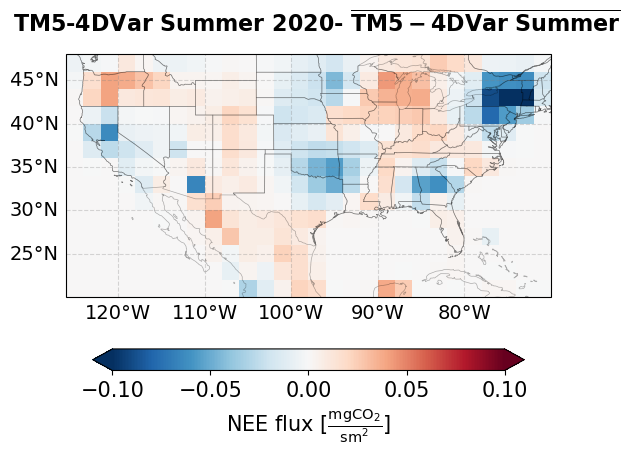

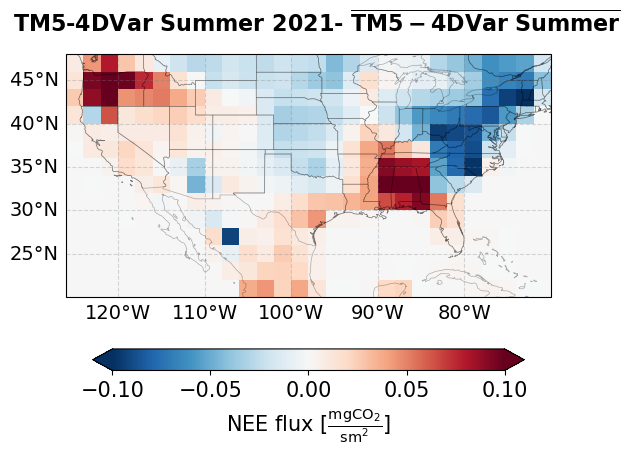

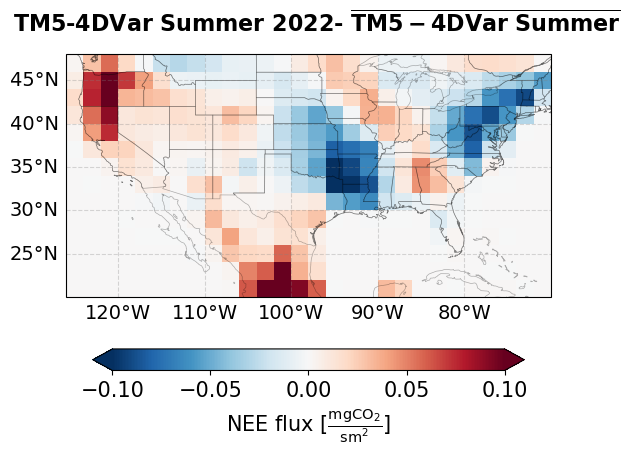

In [80]:
summers=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time.dt.month==6)|(TM54DVar_posterior_flux.time.dt.month==7)&(TM54DVar_posterior_flux.time.dt.month==8),drop=True)
mean_summer_TM5=summers.mean('time')
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("Mean Summer TM5-4DVar", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
plot_map(mean_summer_TM5.CO2_flux_nee*1e6,'mean October total flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.2,vmax=0.2)
#plt.savefig(f'{savefig}/map_mean_october_TM5-4DVar.png',bbox_inches='tight',dpi=500)
plt.close()

for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"TM5-4DVar Summer {year}", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(summers.where(summers.time.dt.year==year,drop=True)).mean('time')
    plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.3,vmax=0.3)
    plt.savefig(f'{savefig}/nee_different_models/pdf/map_{year}_summer_TM5-4DVar.pdf',bbox_inches='tight',dpi=500)
    plt.close()
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"TM5-4DVar Summer {year}- "+r'$\overline{\mathbf{TM5-4DVar\ Summer}}$', fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(summers.where(summers.time.dt.year==year,drop=True)).mean('time') - mean_summer_TM5
    plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.1,vmax=0.1)
    plt.savefig(f'{savefig}/anomalies_different_models/png/map_anomaly_nee_{year}_summer_TM5-4DVar.png',bbox_inches='tight',dpi=500)
    plt.savefig(f'{savefig}/anomalies_different_models/pdf/map_anomaly_nee_{year}_summer_TM5-4DVar.pdf',bbox_inches='tight',dpi=500)
    plt.savefig(f'{savefig}/anomalies_different_models/svg/map_anomaly_nee_{year}_summer_TM5-4DVar.svg',bbox_inches='tight',dpi=500)
    plt.show()


In [21]:
summers=inversion.fluxes.where((inversion.fluxes.time.dt.month==6)|(inversion.fluxes.time.dt.month==7)|(inversion.fluxes.time.dt.month==8),drop=True)
mean_summer=summers.mean('time')
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("mean Summer our posterior", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
plot_map(mean_summer.CO2_flux_nee*1e6,'mean October total flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.2,vmax=0.2)
#plt.savefig(f'{savefig}/map_mean_october_TM5-4DVar.png',bbox_inches='tight',dpi=500)
plt.close()
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"our posterior Summer {year}", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(summers.where(summers.time.dt.year==year,drop=True)).mean('time')
    plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.3,vmax=0.3)
    plt.savefig(f'{savefig}/nee_different_models/png/map_{year}_summer_posterior.png',bbox_inches='tight',dpi=500)
    plt.savefig(f'{savefig}/nee_different_models/pdf/map_{year}_summer_posterior.pdf',bbox_inches='tight',dpi=500)
    plt.savefig(f'{savefig}/nee_different_models/svg/map_{year}_summer_posterior.svg',bbox_inches='tight',dpi=500)
    plt.close()
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"our posterior anomaly Summer {year}", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(summers.where(summers.time.dt.year==year,drop=True)).mean('time') - mean_summer
    plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.08,vmax=0.08)
    plt.savefig(f'{savefig}/anomalies_different_models/png/map_anomaly_nee_{year}_posterior.png',bbox_inches='tight',dpi=500)
    plt.savefig(f'{savefig}/anomalies_different_models/pdf/map_anomaly_nee_{year}_posterior.pdf',bbox_inches='tight',dpi=500)
    plt.savefig(f'{savefig}/anomalies_different_models/svg/map_anomaly_nee_{year}_posterior.svg',bbox_inches='tight',dpi=500)
    plt.close()
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"our posterior anomaly Summer {year}", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(summers.where(summers.time.dt.year==year,drop=True)).mean('time') - mean_summer_TM5
    plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.1,vmax=0.1)
    plt.savefig(f'{savefig}/anomalies_different_models/png/map_anomaly_nee_{year}_posterior-TM5.png',bbox_inches='tight',dpi=500)
    plt.savefig(f'{savefig}/anomalies_different_models/pdf/map_anomaly_nee_{year}_posterior-TM5.pdf',bbox_inches='tight',dpi=500)
    plt.savefig(f'{savefig}/anomalies_different_models/svg/map_anomaly_nee_{year}_posterior-TM5.svg',bbox_inches='tight',dpi=500)
    plt.close()

    if year==2021 or year==2022:
        fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
        fig.suptitle(f"our posterior anomaly Summer {year}", fontsize=16, fontweight='bold')
        fig.subplots_adjust(right=0.85)
        temp=(summers.where(summers.time.dt.year==year,drop=True)).mean('time') - (summers.where(summers.time.dt.year==2020,drop=True)).mean('time')
        plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.1,vmax=0.1)
        plt.savefig(f'{savefig}/anomalies_different_models/png/map_anomaly_nee_{year}_posterior-2020.png',bbox_inches='tight',dpi=500)
        plt.savefig(f'{savefig}/anomalies_different_models/pdf/map_anomaly_nee_{year}_posterior-2020.pdf',bbox_inches='tight',dpi=500)
        plt.savefig(f'{savefig}/anomalies_different_models/svgmap_anomaly_nee_{year}_posterior-2020.svg',bbox_inches='tight',dpi=500)
        plt.close()


In [22]:
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("mean Summer our posterior", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
#plot_map(mean_october.CO2_flux_nee*1e6,'mean October total flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.2,vmax=0.2)
#plt.savefig(f'{savefig}/map_mean_october_TM5-4DVar.png',bbox_inches='tight',dpi=500)
plt.close()
for k in GCP.ensemble_member.values:
    summers=GCP.sel(ensemble_member=k)
    summers=summers.where((summers.time.dt.month==6)|(summers.time.dt.month==7)|(summers.time.dt.month==8),drop=True)
    mean_summer=summers.mean('time')
    for year in [2020,2021,2022]:
        fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
        fig.suptitle(f"{gcp_names[k]} Summer {year}", fontsize=16, fontweight='bold')
        fig.subplots_adjust(right=0.85)
        temp=(summers.where(summers.time.dt.year==year,drop=True)).mean('time')
        plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.3,vmax=0.3)
        plt.savefig(f'{savefig}/nee_different_models/png/map_{year}_summer_{gcp_names[k]}.png',bbox_inches='tight',dpi=500)
        plt.savefig(f'{savefig}/nee_different_models/pdf/map_{year}_summer_{gcp_names[k]}.pdf',bbox_inches='tight',dpi=500)
        plt.savefig(f'{savefig}/nee_different_models/svg/map_{year}_summer_{gcp_names[k]}.svg',bbox_inches='tight',dpi=500)
        plt.close()
        fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
        fig.suptitle(f"{gcp_names[k]} anomaly Summer {year}", fontsize=16, fontweight='bold')
        fig.subplots_adjust(right=0.85)
        temp=(summers.where(summers.time.dt.year==year,drop=True)).mean('time') - mean_summer
        plot_map(temp.CO2_flux_nee*1e6,'NEE flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.1,vmax=0.1)
        plt.savefig(f'{savefig}/anomalies_different_models/png/map_anomaly_nee_{year}_summer_{gcp_names[k]}.png',bbox_inches='tight',dpi=500)
        plt.savefig(f'{savefig}/anomalies_different_models/pdf/map_anomaly_nee_{year}_summer_{gcp_names[k]}.pdf',bbox_inches='tight',dpi=500)
        plt.savefig(f'{savefig}/anomalies_different_models/svg/map_anomaly_nee_{year}_summer_{gcp_names[k]}.svg',bbox_inches='tight',dpi=500)
        plt.close()
        


In [25]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')
#TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(TM54DVar_posterior_flux.time<=pd.to_datetime(analysis_end_date)),drop=True)

In [26]:
TM54DVar_posterior_flux_october=TM54DVar_posterior_flux.where(TM54DVar_posterior_flux.time.dt.month==10,drop=True)
TM54DVar_posterior_flux_october=TM54DVar_posterior_flux_october.where((TM54DVar_posterior_flux_october.latitude>=analy_region_lat[0])& (TM54DVar_posterior_flux_october.latitude<=analy_region_lat[1]),drop=True)
TM54DVar_posterior_flux_october=TM54DVar_posterior_flux_october.where((TM54DVar_posterior_flux_october.longitude>=analy_region_lon[0])& (TM54DVar_posterior_flux_october.longitude<=analy_region_lon[1]),drop=True)

In [27]:
TM54DVar_posterior_flux_october

<xarray.Dataset> Size: 1MB
Dimensions:         (time: 62, latitude: 14, longitude: 28)
Coordinates:
  * time            (time) datetime64[ns] 496B 2009-10-05 ... 2022-10-31
  * latitude        (latitude) float64 112B 21.0 23.0 25.0 ... 43.0 45.0 47.0
  * longitude       (longitude) float64 224B -125.0 -123.0 ... -73.0 -71.0
Data variables:
    grid_cell_area  (time, latitude, longitude) float64 194kB 4.617e+10 ... 3...
    CO2_flux_nee    (time, latitude, longitude) float64 194kB 0.0 ... 5.761e-08
    CO2_flux_fire   (time, latitude, longitude) float64 194kB 0.0 ... 5.779e-12
    CO2_flux_oce    (time, latitude, longitude) float64 194kB 5.818e-10 ... 0.0
    CO2_flux_fos    (time, latitude, longitude) float64 194kB 1.804e-11 ... 1...
    total_flux      (time, latitude, longitude) float64 194kB 5.998e-10 ... 7...

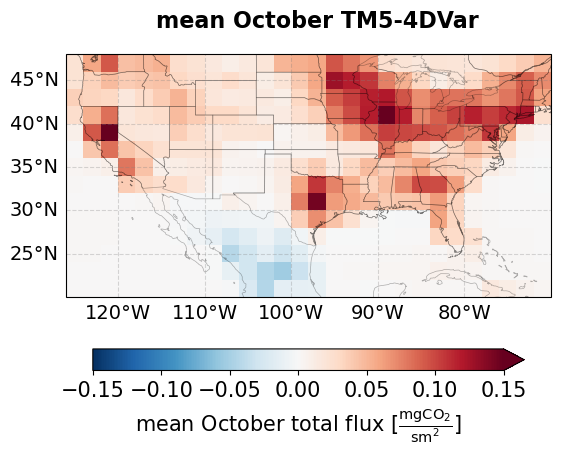

In [64]:
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("mean October TM5-4DVar", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
TM54DVar_posterior_flux_october_mean=(TM54DVar_posterior_flux_october.mean('time').total_flux)*1e6
plot_map(TM54DVar_posterior_flux_october_mean,'mean October total flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.15,vmax=0.15)
plt.savefig(f'{savefig}/map_mean_october_TM5-4DVar.png',bbox_inches='tight',dpi=500)


In [75]:
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"TM5-4DVar flux anomaly 10/{year}", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(TM54DVar_posterior_flux_october.where(TM54DVar_posterior_flux_october.time.dt.year==year,drop=True)).mean('time').total_flux*1e6
    anomaly=temp-TM54DVar_posterior_flux_october_mean
    plot_map(anomaly,'$\\mathrm{\\frac{mgCO_2}{s m^2}}$',axs,vmin=-0.09,vmax=0.09)
    plt.savefig(f'{savefig}/map_anomaly_{year}_october_TM5-4DVar.png',bbox_inches='tight',dpi=500)
    plt.close()

# Our posterior October

In [30]:
path='inversions_new/TM5_3_years/'
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

inversion=data(path,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3)
inversion.read_data()

In [31]:
inversion_october=inversion.fluxes.where(inversion.fluxes.time.dt.month==10,drop=True)
inversion_october=inversion_october.where((inversion_october.latitude>=analy_region_lat[0])& (inversion_october.latitude<=analy_region_lat[1]),drop=True)
inversion_october=inversion_october.where((inversion_october.longitude>=analy_region_lon[0])& (inversion_october.longitude<=analy_region_lon[1]),drop=True)

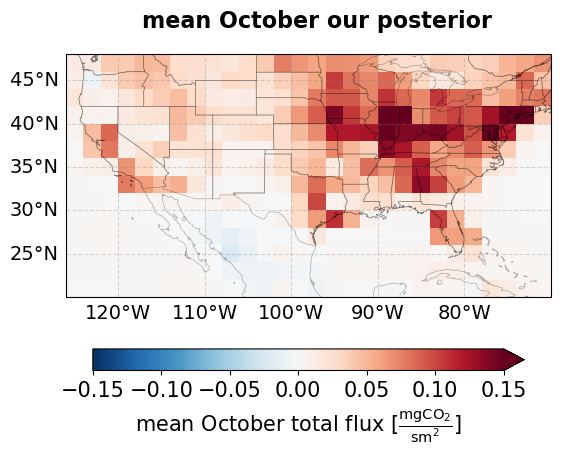

In [66]:
fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("mean October our posterior", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
inversion_october_mean=(inversion_october.mean('time').TM5_posterior_flux)*1e6
plot_map(inversion_october_mean,'mean October total flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',axs,vmin=-0.15,vmax=0.15)
plt.savefig(f'{savefig}/map_mean_october_posterior.png',bbox_inches='tight',dpi=500)


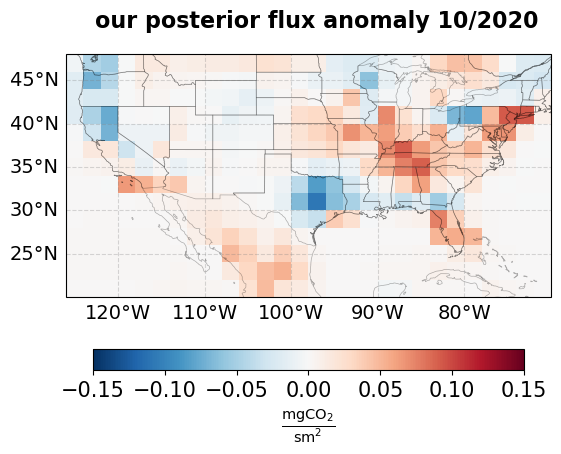

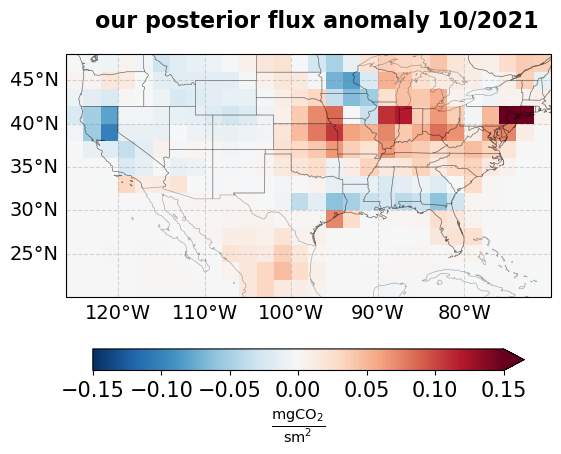

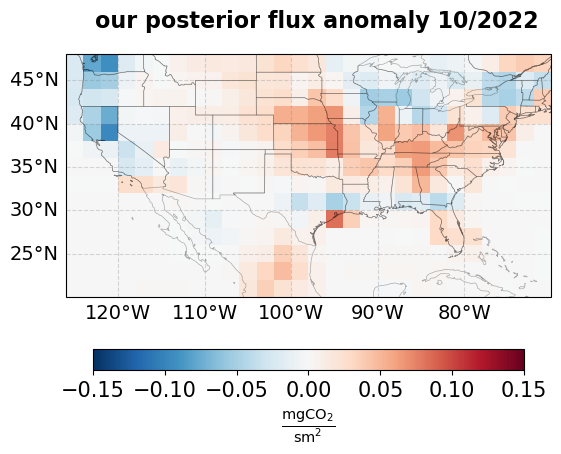

In [76]:
for year in [2020,2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"our posterior flux anomaly 10/{year}", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(inversion_october.where(inversion_october.time.dt.year==year,drop=True)).mean('time').TM5_posterior_flux*1e6
    anomaly=temp-TM54DVar_posterior_flux_october_mean
    plot_map(anomaly,'$\\mathrm{\\frac{mgCO_2}{s m^2}}$',axs,vmin=-0.15,vmax=0.15)
    plt.savefig(f'{savefig}/map_anomaly_{year}_october_posterior.png',bbox_inches='tight',dpi=500)
    plt.show()

In [77]:
for year in [2021,2022]:
    fig,axs=plt.subplots(1,1,figsize=(7,4.5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"our posterior 10/{year} - 10/2020", fontsize=16, fontweight='bold')
    fig.subplots_adjust(right=0.85)
    temp=(inversion_october.where(inversion_october.time.dt.year==year,drop=True)).mean('time').TM5_posterior_flux*1e6
    anomaly=temp-((inversion_october.where(inversion_october.time.dt.year==2020,drop=True)).mean('time').TM5_posterior_flux*1e6)
    plot_map(anomaly,'$\\mathrm{\\frac{mgCO_2}{s m^2}}$',axs,vmin=-0.15,vmax=0.15)
    plt.savefig(f'{savefig}/map_anomaly_{year}_october_posterior-2020.png',bbox_inches='tight',dpi=500)
    plt.close()